In [39]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

IMG_PATH     = 'a2images/the_berry_farms_sunflower_field.jpeg'
SIGMA_MIN    = 2
SIGMA_MAX    = 20.0
N_SCALES     = 25
THRESH_LOG   = 0.45
THRESH_DOG   = 0.45
BRIGHT_BLOBS = False
N_LARGEST    = 5



In [40]:
# ---------------- channels ----------------
def to_gray_channel(im_bgr):
    return cv.cvtColor(im_bgr, cv.COLOR_BGR2GRAY).astype(np.float64) / 255.0


def to_yellow_channel(im_bgr):
    f = im_bgr.astype(np.float64) / 255.0
    b, g, r = f[..., 0], f[..., 1], f[..., 2]
    y = np.minimum(r, g) - b                      # strong only for yellow pixels
    lo, hi = np.percentile(y, 1), np.percentile(y, 99)
    return np.clip((y - lo) / (hi - lo + 1e-9), 0.0, 1.0)



In [41]:
def extrema_3d(resp, thr, bright=True):
    r = -resp if bright else resp
    is_max = (r == maximum_filter(r, size=(3, 3, 3)))
    keep = is_max & (r > thr * r.max())
    keep[0] = False
    keep[-1] = False
    k, y, x = np.nonzero(keep)
    return k, y, x, r[k, y, x]


def suppress_overlaps(blobs):
    """Keep the strongest blob; drop any blob whose circle touches a kept circle.
    Two circles are separate only if centre distance >= r1 + r2  -> no overlap at all."""
    kept = []
    for x, y, s, resp in sorted(blobs, key=lambda b: -b[3]):
        r = np.sqrt(2) * s
        if all(np.hypot(x - xk, y - yk) >= r + np.sqrt(2) * sk
               for xk, yk, sk, _ in kept):
            kept.append((x, y, s, resp))
    return kept


# ---------------- Method 1: Laplacian of Gaussian ----------------
def laplacian_kernel(sigma):
    half = int(np.ceil(4 * sigma))
    ax = np.arange(-half, half + 1, dtype=np.float64)
    xx, yy = np.meshgrid(ax, ax)
    r2 = xx ** 2 + yy ** 2
    k = -(1.0 / (np.pi * sigma ** 4)) * (1.0 - r2 / (2 * sigma ** 2)) * np.exp(-r2 / (2 * sigma ** 2))
    return k - k.mean()


def method_laplacian(chan, sigmas):
    stack = np.stack([(s ** 2) * cv.filter2D(chan, cv.CV_64F, laplacian_kernel(s),
                                             borderType=cv.BORDER_REFLECT) for s in sigmas])
    k, y, x, resp = extrema_3d(stack, THRESH_LOG, BRIGHT_BLOBS)
    blobs = [(int(xi), int(yi), float(sigmas[ki]), float(v)) for ki, yi, xi, v in zip(k, y, x, resp)]
    return suppress_overlaps(blobs)




=== Grayscale - Laplacian of Gaussian ===
blobs detected: 63
rank      x      y    sigma   radius
   1    337    165    12.38    17.51
   2    293    169    12.38    17.51
   3      0    275     7.66    10.84
   4    282    338     6.96     9.84
   5    223    174     6.32     8.94

=== Grayscale - Difference of Gaussians ===
blobs detected: 59
rank      x      y    sigma   radius
   1    338    165    13.21    18.69
   2    293    169    12.05    17.04
   3      0    275     7.60    10.75
   4    282    338     6.93     9.81
   5    223    174     6.32     8.94

=== Yellow scale - Laplacian of Gaussian ===
blobs detected: 61
rank      x      y    sigma   radius
   1      0    102    13.63    19.27
   2      0    275     7.66    10.84
   3    282    338     6.96     9.84
   4    106    255     5.75     8.13
   5    178    261     5.75     8.13

=== Yellow scale - Difference of Gaussians ===
blobs detected: 64
rank      x      y    sigma   radius
   1      0    102    13.21    18.69
  

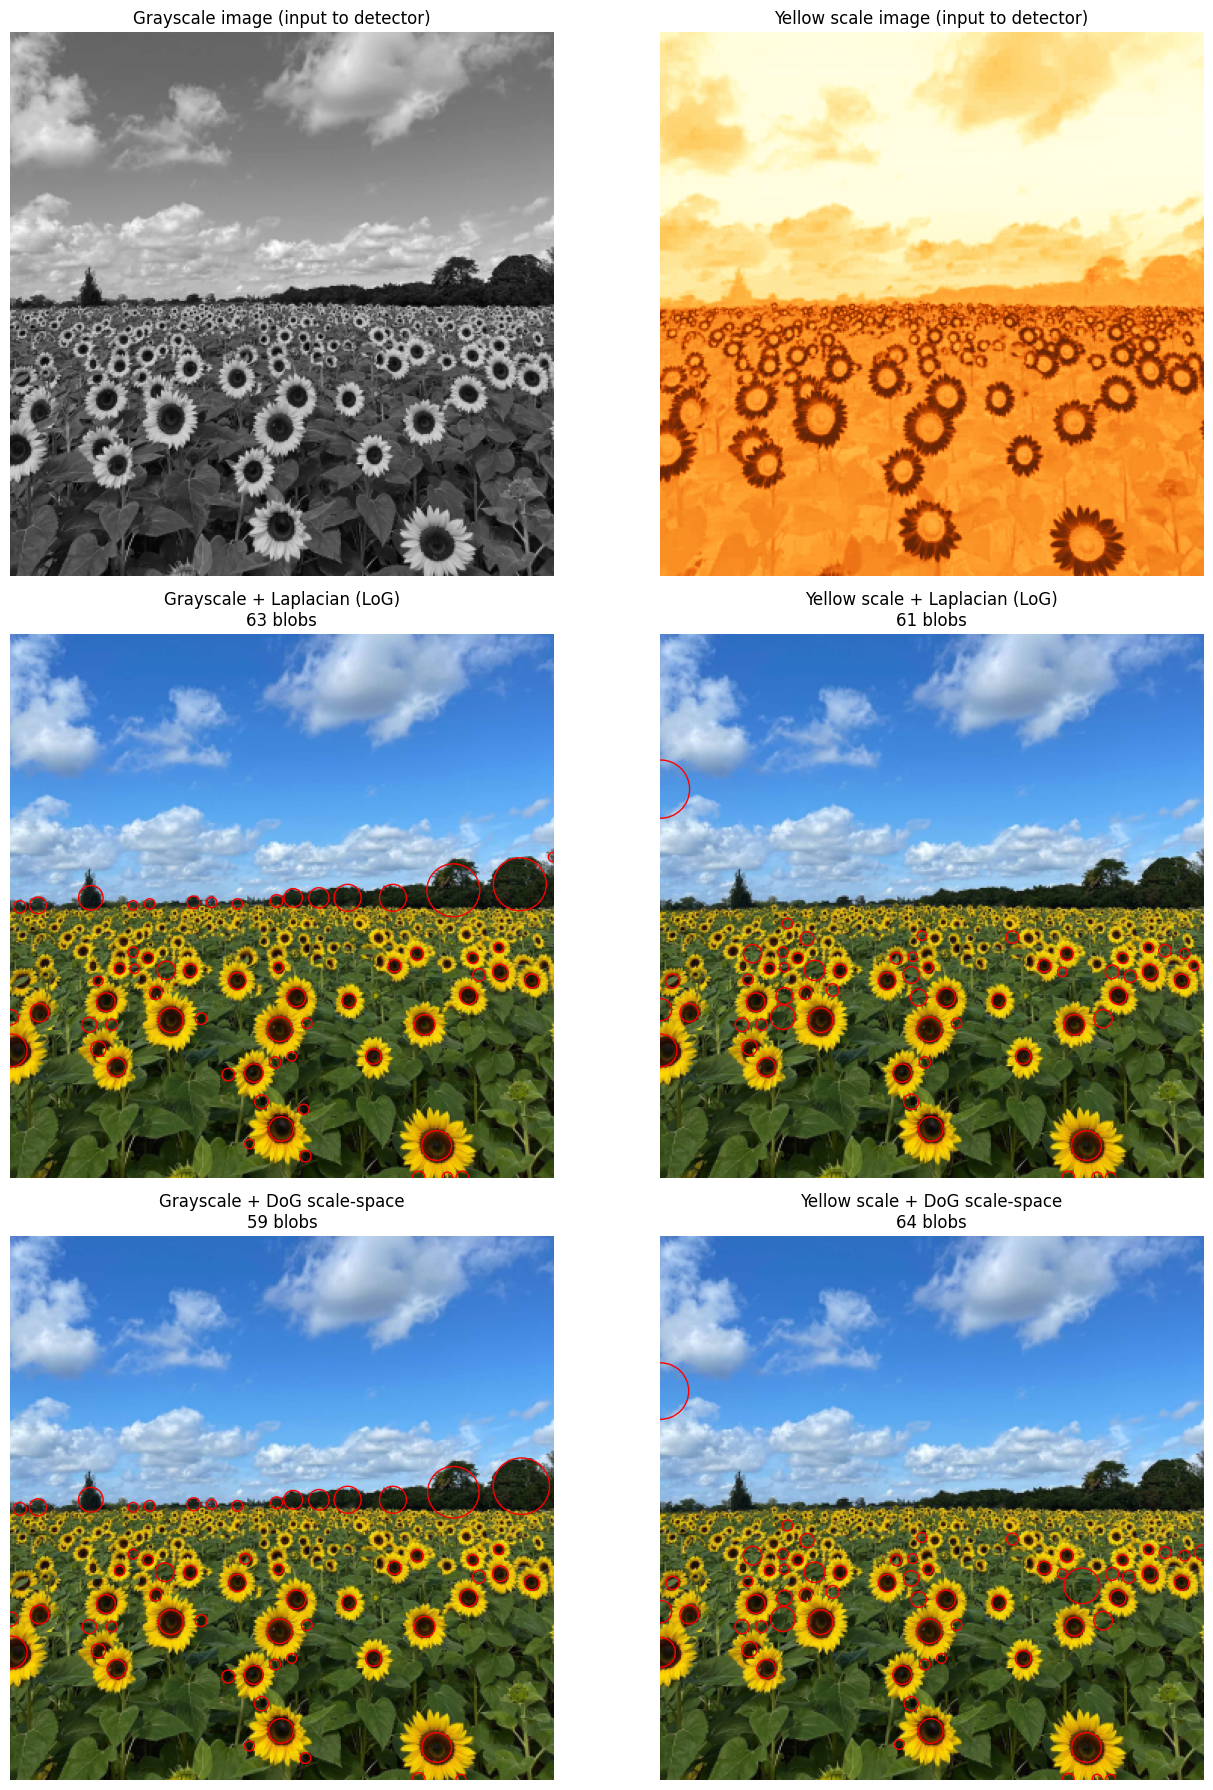

In [42]:

# ---------------- Method 2: Difference of Gaussians ----------------
def method_scale_space(chan, sigmas_edges):
    gauss = [cv.GaussianBlur(chan, (0, 0), s) for s in sigmas_edges]
    dog = np.stack([gauss[i + 1] - gauss[i] for i in range(len(gauss) - 1)])
    sig_level = np.sqrt(sigmas_edges[:-1] * sigmas_edges[1:])
    k, y, x, resp = extrema_3d(dog, THRESH_DOG, BRIGHT_BLOBS)
    blobs = [(int(xi), int(yi), float(sig_level[ki]), float(v)) for ki, yi, xi, v in zip(k, y, x, resp)]
    return suppress_overlaps(blobs), sig_level


def report(name, blobs):
    print(f'\n=== {name} ===')
    print(f'blobs detected: {len(blobs)}')
    print(f'{"rank":>4} {"x":>6} {"y":>6} {"sigma":>8} {"radius":>8}')
    for i, (x, y, s, _) in enumerate(sorted(blobs, key=lambda b: -b[2])[:N_LARGEST], 1):
        print(f'{i:>4} {x:>6} {y:>6} {s:>8.2f} {np.sqrt(2) * s:>8.2f}')


def draw(ax, im_rgb, blobs, title):
    ax.imshow(im_rgb)
    for x, y, s, _ in blobs:
        ax.add_patch(plt.Circle((x, y), np.sqrt(2) * s, color='r', fill=False, lw=1.0))
    ax.set_title(f'{title}\n{len(blobs)} blobs')
    ax.axis('off')


# ---------------- main ----------------
def main(img=None):
    im = img if img is not None else cv.imread(IMG_PATH, cv.IMREAD_REDUCED_COLOR_4)
    if im is None:
        raise FileNotFoundError(IMG_PATH)
    im_rgb = cv.cvtColor(im, cv.COLOR_BGR2RGB)

    channels = {'Grayscale': to_gray_channel(im), 'Yellow scale': to_yellow_channel(im)}

    sigmas = np.geomspace(SIGMA_MIN, SIGMA_MAX, N_SCALES)
    k = (SIGMA_MAX / SIGMA_MIN) ** (1.0 / N_SCALES)
    sig_edges = SIGMA_MIN * k ** np.arange(N_SCALES + 1)

    # row 0: the channel images, row 1: LoG blobs, row 2: DoG blobs
    fig, axs = plt.subplots(3, 2, figsize=(14, 18))
    for col, (name, chan) in enumerate(channels.items()):
        cv.imwrite(f'q1_{name.split()[0].lower()}_channel.png', (chan * 255).astype(np.uint8))

        blobs_log = method_laplacian(chan, sigmas)
        blobs_dog, _ = method_scale_space(chan, sig_edges)
        report(f'{name} - Laplacian of Gaussian', blobs_log)
        report(f'{name} - Difference of Gaussians', blobs_dog)

        axs[0, col].imshow(chan, cmap='gray' if name == 'Grayscale' else 'YlOrBr')
        axs[0, col].set_title(f'{name} image (input to detector)')
        axs[0, col].axis('off')
        draw(axs[1, col], im_rgb, blobs_log, f'{name} + Laplacian (LoG)')
        draw(axs[2, col], im_rgb, blobs_dog, f'{name} + DoG scale-space')

    plt.tight_layout()
    plt.savefig('q1_result.png', dpi=120)
    plt.show()


if __name__ == '__main__':
    main()